# Model comparison report: Chicago crash injury prediction (logistic regression, decision tree, random forest)

Reads the result files written by the three model notebooks and builds ONE report
(model_comparison_report.html) organised by the assignment's dimensions: predictive performance,
generalization, class-specific performance, calibration, robustness, uncertainty, computational
efficiency, interpretability, subsets, and scenario-based model selection.

**How to use**

1. Put this notebook in the folder that holds the result files of all three models (`logreg_*`, `dt_*`, `rf_*`, plus the logistic regression's `subgroup_results.csv`, `robustness_results.csv`, `permutation_importance.csv` and `coefficients.csv`), or set `FOLDER` in the config cell.
2. Run all cells. The paired bootstrap takes about 1-2 minutes; lower `N_BOOT` for a quick test.
3. Open `model_comparison_report.html` in a browser. Print it to PDF, or copy tables into your write-up.

Files that are missing are skipped, and the report says which. Every statement in *Key findings* is generated from the numbers, so check it against the tables before quoting it.

In [1]:
%matplotlib inline
import os
import re
import io
import html
import base64
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
    matthews_corrcoef, roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    confusion_matrix, roc_curve, precision_recall_curve,
)

warnings.filterwarnings("ignore")

## CONFIG

Edit `SCENARIOS` (what matters in each real-world setting) and `INTERPRETABILITY_SCORE` (a judgment you should justify in the report). Everything else can stay as is.

In [2]:
FOLDER = "."                        # folder holding the result files of all three models
OUTPUT_HTML = "model_comparison_report.html"
ALSO_EXPORT_EXCEL = False           # True = also write model_comparison_tables.xlsx (needs openpyxl)
N_BOOT = 200                        # paired bootstrap resamples (about 1-3 minutes)
SEED = 42
TIE_TOL = 0.01                      # scorecard: values within 1% (relative) of each other count as tied; 0 = strict
MIN_GROUP_N = 500                   # subgroups smaller than this are flagged as unreliable

MODELS = {                          # display name -> file prefix used by that model's notebook
    "Logistic regression": "logreg",
    "Decision tree": "dt",
    "Random forest": "rf",
}
# A judgment call, not a measurement: 1 (opaque) to 5 (fully readable). Justify your choice in the report.
INTERPRETABILITY_SCORE = {"Logistic regression": 4, "Decision tree": 5, "Random forest": 2}

# Scenario weights: higher weight = that dimension matters more in that real-world setting.
SCENARIOS = {
    "Emergency dispatch (flag nearly every injury crash)":
        {"precision_at_recall90": 4, "pr_auc": 2, "robust_missing30": 1, "inference_time": 1},
    "Limited follow-up capacity (can act on the top 10% of crashes)":
        {"precision_at_top10": 4, "pr_auc": 2, "roc_auc": 1},
    "Calibrated risk estimates for planning and budgeting":
        {"log_loss": 3, "ece": 3, "pr_auc": 1, "worst_group_auc": 1},
    "Messy or changing data (missing values, new season or area)":
        {"robust_missing30": 3, "robust_shift": 3, "worst_group_auc": 1, "pr_auc": 1},
    "Cheap and explainable (policy briefings, simple deployment)":
        {"interpretability": 3, "train_time": 1, "inference_time": 1, "model_size": 1, "pr_auc": 2},
    "Balanced (every dimension equal)":
        {"pr_auc": 1, "roc_auc": 1, "log_loss": 1, "ece": 1, "precision_at_recall90": 1, "precision_at_top10": 1,
         "robust_missing30": 1, "robust_shift": 1, "worst_group_auc": 1, "train_time": 1,
         "inference_time": 1, "model_size": 1, "interpretability": 1},
}
FEATURE_GROUPS = {   # used for the grouped importance view (sum of member permutation importances)
    "Crash type": ["FIRST_CRASH_TYPE"],
    "Number of units": ["NUM_UNITS"],
    "Time of day": ["CRASH_HOUR", "HOUR_SIN", "HOUR_COS"],
    "Calendar (day, weekend, month)": ["CRASH_DAY_OF_WEEK", "IS_WEEKEND", "CRASH_MONTH"],
    "Weather and surface": ["WEATHER_CONDITION", "ROADWAY_SURFACE_COND", "ROAD_DEFECT"],
    "Lighting": ["LIGHTING_CONDITION"],
    "Road layout and controls": ["POSTED_SPEED_LIMIT", "LANE_CNT", "ALIGNMENT", "TRAFFICWAY_TYPE",
                                 "TRAFFIC_CONTROL_DEVICE", "DEVICE_CONDITION", "INTERSECTION_RELATED_I"],
    "Crash circumstances": ["HIT_AND_RUN_I", "NOT_RIGHT_OF_WAY_I"],
}
# ============================================================================
PALETTE = ["#1f77b4", "#2ca02c", "#d62728", "#9467bd", "#ff7f0e"]
COLORS = {m: PALETTE[i % len(PALETTE)] for i, m in enumerate(MODELS)}
LOWER_BETTER = {"log_loss", "brier", "ece"}

## 1. HELPERS

In [3]:
TABLES = {}
FINDINGS = []     # (dimension, sentence)
WARNINGS = []


class Sec:
    def __init__(self, title):
        self.title = title
        self.anchor = re.sub(r"[^a-z0-9]+", "-", title.lower()).strip("-")
        self.parts = []

    def h(self, t):
        self.parts.append(f"<h3>{html.escape(t)}</h3>")

    def p(self, t):
        self.parts.append(f"<p>{html.escape(t)}</p>")

    def note(self, t):
        self.parts.append(f'<p class="note">{html.escape(t)}</p>')

    def raw(self, t):
        self.parts.append(t)

    def img(self, fig):
        buf = io.BytesIO()
        fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
        self.parts.append('<img alt="chart" src="data:image/png;base64,%s">' % base64.b64encode(buf.getvalue()).decode())
        plt.show()

    def table(self, df, row_dir=None, col_dir=None, digits=4, index=True, name=None):
        self.parts.append(render_table(df, row_dir, col_dir, digits, index))
        if name:
            TABLES[re.sub(r"[\[\]\*\?/\\:]", "", name)[:31]] = df.copy()

    def html(self):
        return f'<section id="{self.anchor}"><h2>{html.escape(self.title)}</h2>' + "".join(self.parts) + "</section>"


def fmt_val(v, digits):
    if isinstance(v, (float, np.floating)):
        if np.isnan(v):
            return ""
        return f"{v:,.0f}" if abs(v) >= 1000 else f"{v:.{digits}f}"
    if isinstance(v, (int, np.integer)):
        return f"{v:,}"
    return html.escape(str(v))


def render_table(df, row_dir=None, col_dir=None, digits=4, index=True):
    best = np.zeros(df.shape, dtype=bool)
    num = df.apply(pd.to_numeric, errors="coerce")
    if row_dir:
        for i, r in enumerate(df.index):
            d = row_dir.get(r)
            vals = num.iloc[i].values.astype(float)
            if d and np.isfinite(vals).sum() >= 2:
                if d == "absmin":
                    best[i] = np.abs(vals) == np.nanmin(np.abs(vals))
                else:
                    tgt = np.nanmax(vals) if d == "max" else np.nanmin(vals)
                    best[i] = vals == tgt
    if col_dir:
        for j, c in enumerate(df.columns):
            d = col_dir.get(c)
            vals = num.iloc[:, j].values.astype(float)
            if d and np.isfinite(vals).sum() >= 2:
                if d == "absmin":
                    best[:, j] = np.abs(vals) == np.nanmin(np.abs(vals))
                else:
                    tgt = np.nanmax(vals) if d == "max" else np.nanmin(vals)
                    best[:, j] = vals == tgt
    head = "<tr>" + ("<th></th>" if index else "") + "".join(f"<th>{html.escape(str(c))}</th>" for c in df.columns) + "</tr>"
    rows = []
    for i in range(len(df)):
        tds = [f"<th>{html.escape(str(df.index[i]))}</th>"] if index else []
        for j in range(df.shape[1]):
            s = fmt_val(df.iat[i, j], digits)
            tds.append(f'<td class="best"><b>{s}</b></td>' if best[i, j] else f"<td>{s}</td>")
        rows.append("<tr>" + "".join(tds) + "</tr>")
    return f'<div class="tbl"><table>{head}{"".join(rows)}</table></div>'


def ece_score(y, p, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(p, bins) - 1, 0, n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            ece += m.mean() * abs(y[m].mean() - p[m].mean())
    return ece


def metrics(y, p, thr=0.5):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    yhat = (p >= thr).astype(int)
    return {
        "accuracy": accuracy_score(y, yhat),
        "precision": precision_score(y, yhat, zero_division=0),
        "recall": recall_score(y, yhat, zero_division=0),
        "f1": f1_score(y, yhat, zero_division=0),
        "balanced_acc": balanced_accuracy_score(y, yhat),
        "mcc": matthews_corrcoef(y, yhat),
        "roc_auc": roc_auc_score(y, p),
        "pr_auc": average_precision_score(y, p),
        "log_loss": log_loss(y, p),
        "brier": brier_score_loss(y, p),
        "ece": ece_score(y, p),
    }


def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.argmax(f1)])


def precision_at_recall(y, p, target):
    prec, rec, _ = precision_recall_curve(y, p)
    ok = rec >= target
    return float(prec[ok].max()) if ok.any() else np.nan


def topk(y, p, frac):
    k = max(1, int(frac * len(y)))
    idx = np.argsort(-p, kind="stable")[:k]
    return float(y[idx].mean()), float(y[idx].sum() / max(y.sum(), 1))   # precision, recall


def safe_div(a, b):
    return a / b if b else np.nan


def find_file(key, artifact, ext="csv"):
    names = [f"{key}_{artifact}.{ext}"]
    if key == "logreg":      # the original logistic regression script saved some files without a prefix
        names.append(f"{artifact}.{ext}")
    for n in names:
        fp = os.path.join(FOLDER, n)
        if os.path.exists(fp):
            return fp
    return None


def best_of(series, higher=True):
    s = series.dropna()
    return (s.idxmax() if higher else s.idxmin()) if len(s) else None


def cluster_scores(values, higher):
    """1.0 = best group, 0.0 = worst group; values within TIE_TOL (relative) of each other share a group."""
    v = values.dropna().sort_values(ascending=not higher)
    if v.empty:
        return pd.Series(dtype=float)
    groups, cur, last = [], [], None
    for name, val in v.items():
        if last is not None and abs(val - last) > TIE_TOL * max(abs(v.iloc[0]), 1e-12):
            groups.append(cur)
            cur = []
        cur.append(name)
        last = val
    groups.append(cur)
    out = {}
    for k, g in enumerate(groups):
        for name in g:
            out[name] = 1.0 if len(groups) == 1 else 1 - k / (len(groups) - 1)
    return pd.Series(out)

## 2. LOAD FILES

Prints which result files were found for each model.

In [4]:
ARTIFACTS = ["run_info", "test_metrics_by_threshold", "generalization", "calibration", "bootstrap",
             "subgroup_results", "robustness_results", "shift_results", "permutation_importance",
             "importance", "coefficients", "tuning", "test_predictions"]
INDEXED = {"run_info", "test_metrics_by_threshold", "generalization", "calibration", "bootstrap",
           "robustness_results", "shift_results"}

ART = {m: {} for m in MODELS}
RULES = {}
inventory = []
for m, key in MODELS.items():
    for a in ARTIFACTS:
        fp = find_file(key, a)
        if fp:
            ART[m][a] = pd.read_csv(fp, index_col=0 if a in INDEXED else None, low_memory=False,
                                    dtype=str if a == "run_info" else None)
        inventory.append({"model": m, "file": os.path.basename(fp) if fp else f"{key}_{a}.csv", "found": "yes" if fp else "MISSING"})
    rp = find_file(key, "tree_rules", "txt")
    if rp:
        RULES[m] = open(rp).read()
inv = pd.DataFrame(inventory)
print(inv.groupby(["model", "found"]).size().unstack(fill_value=0))
missing_core = inv[(inv["found"] == "MISSING") & inv["file"].str.contains("test_predictions|run_info")]
if len(missing_core):
    print("\nMissing core files:\n", missing_core.to_string(index=False))

USABLE = [m for m in MODELS if "test_predictions" in ART[m]]
if len(USABLE) < 2:
    raise RuntimeError("Need prediction files for at least two models. Check FOLDER and the *_test_predictions.csv files.")
print("\nModels in the comparison:", USABLE)


def num(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "None"
    try:
        return float(v)
    except (TypeError, ValueError):
        return v


RUN = {}
for m in MODELS:
    ri = ART[m].get("run_info")
    RUN[m] = {} if ri is None else {k: (v if k == "test_fingerprint" else num(v)) for k, v in ri["value"].items()}

found                MISSING  yes
model                            
Decision tree              1   12
Logistic regression        2   11
Random forest              1   12

Models in the comparison: ['Logistic regression', 'Decision tree', 'Random forest']


## 3. DATA CHECKS

Confirms all models were tested on the same crashes. If it warns about different labels or fingerprints, fix that before trusting any comparison.

In [5]:
sec_data = Sec("Data checks")
D = None
for m in USABLE:
    key = MODELS[m]
    dfp = ART[m]["test_predictions"]
    want = {"row_index": "row_index", "y_true": f"y::{m}", f"p_{key}": f"p::{m}",
            f"p_{key}_platt": f"pp::{m}", f"p_{key}_isotonic": f"pi::{m}"}
    dfp = dfp[[c for c in want if c in dfp.columns]].rename(columns=want)
    D = dfp if D is None else D.merge(dfp, on="row_index", how="inner")

y_cols = [f"y::{m}" for m in USABLE]
agree = all((D[y_cols[0]] == D[c]).all() for c in y_cols[1:])
y = D[y_cols[0]].values.astype(int)
P = {m: D[f"p::{m}"].values.astype(float) for m in USABLE}
P_platt = {m: D[f"pp::{m}"].values.astype(float) for m in USABLE if f"pp::{m}" in D}
P_iso = {m: D[f"pi::{m}"].values.astype(float) for m in USABLE if f"pi::{m}" in D}

rows = []
for m in USABLE:
    n_file = len(ART[m]["test_predictions"])
    rows.append({"Model": m, "Test rows in file": n_file, "Rows shared by all models": len(D),
                 "Test fingerprint": RUN[m].get("test_fingerprint", "not saved"),
                 "Cores reported": RUN[m].get("cpu_cores", np.nan)})
data_tbl = pd.DataFrame(rows).set_index("Model")
fps = {RUN[m].get("test_fingerprint") for m in USABLE if RUN[m].get("test_fingerprint")}
n_files = {len(ART[m]["test_predictions"]) for m in USABLE}
if not agree:
    WARNINGS.append("The true labels differ between the models' prediction files, so they were NOT evaluated on the same rows. Re-run all models with identical data and settings before trusting any comparison.")
if len(fps) > 1:
    WARNINGS.append(f"Test fingerprints differ between models ({sorted(fps)}). The models were split differently, so differences may come from the data, not the models.")
if len(n_files) > 1 or len(D) != max(n_files):
    WARNINGS.append(f"Prediction files have different row counts ({sorted(n_files)}); only the {len(D):,} shared rows are used.")

sec_data.p(f"All comparisons use the {len(D):,} test crashes that every model scored. The injury rate in this test set is {y.mean():.2%}.")
sec_data.table(data_tbl, digits=0, name="Data checks")
sec_data.p("Labels agree across all prediction files: " + ("yes." if agree else "NO (see warning at the top)."))
sec_data.p("Test fingerprints match: " + ("yes." if len(fps) == 1 else ("no (see warning)." if fps else "not available (run-info files missing).")))
miss = inv[inv["found"] == "MISSING"]
if len(miss):
    sec_data.note("Result files not found (the related tables are skipped): " + ", ".join(miss["file"]))

# thresholds chosen on validation by each model's own notebook
THR_F1, THR_R90 = {}, {}
for m in USABLE:
    t1, t2 = RUN[m].get("threshold_max_f1"), RUN[m].get("threshold_recall90")
    if not isinstance(t1, float):
        t1 = best_f1_threshold(y, P[m])
        WARNINGS.append(f"{m}: the saved max-F1 threshold was not found, so one was chosen on the test set (slightly optimistic).")
    if not isinstance(t2, float):
        prec, rec, thr = precision_recall_curve(y, P[m])
        ok = np.where(rec[:-1] >= 0.90)[0]
        t2 = float(thr[ok[-1]]) if len(ok) else float(thr[0])
    THR_F1[m], THR_R90[m] = t1, t2

# reconstructed metrics must match what each notebook saved
chk = []
for m in USABLE:
    mt = ART[m].get("test_metrics_by_threshold")
    if mt is not None and "max_F1" in mt.index:
        mine, saved = metrics(y, P[m], THR_F1[m]), mt.loc["max_F1"].astype(float)
        diffs = {k: abs(mine[k] - saved[k]) for k in ["roc_auc", "pr_auc", "log_loss", "f1"] if k in saved}
        chk.append({"Model": m, "Largest difference vs saved metrics": max(diffs.values()),
                    "Status": "match" if max(diffs.values()) < 1e-3 else "MISMATCH"})
        if max(diffs.values()) >= 1e-3:
            WARNINGS.append(f"{m}: metrics recomputed from the prediction file differ from the metrics file the notebook saved.")
if chk:
    sec_data.h("Do the prediction files reproduce each notebook's saved metrics?")
    sec_data.table(pd.DataFrame(chk).set_index("Model"), digits=6)

## 4. PREDICTIVE PERFORMANCE

Metrics are recomputed from the saved test predictions, so every model is scored by identical code on identical rows.

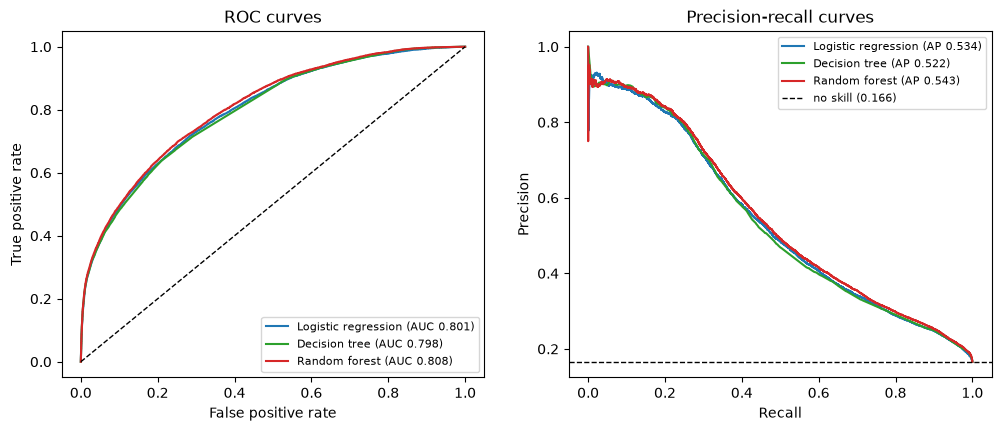

In [6]:
sec_pred = Sec("Predictive performance")
sec_score = Sec("Scorecard: which model is best?")

prev = y.mean()
ref = pd.DataFrame({"No-skill reference": {
    "accuracy (always predict no injury)": 1 - prev,
    "PR-AUC (= injury rate)": prev,
    "ROC-AUC": 0.5,
    "log loss (constant prediction)": float(log_loss(y, np.full(len(y), prev))),
    "Brier (constant prediction)": float(prev * (1 - prev)),
}})
sec_pred.h("Reference point: a model with no skill")
sec_pred.table(ref, name="No-skill reference")
sec_pred.note("Accuracy only means something relative to the first row. Because most crashes involve no injury, a model can look accurate while missing most injury crashes.")

SC, DIRS = {}, {}
for m in USABLE:
    p = P[m]
    base = metrics(y, p, 0.5)
    for k in ["roc_auc", "pr_auc", "log_loss", "brier", "ece"]:
        SC.setdefault(k, {})[m] = base[k]
    SC.setdefault("precision @ recall 0.90 (any threshold)", {})[m] = precision_at_recall(y, p, 0.90)
    SC.setdefault("precision @ top 10% of crashes flagged", {})[m] = topk(y, p, 0.10)[0]
    SC.setdefault("recall @ top 10% of crashes flagged", {})[m] = topk(y, p, 0.10)[1]
    for tname, thr in [("default 0.5", 0.5), ("model's own max-F1 threshold", THR_F1[m])]:
        mm = metrics(y, p, thr)
        for k in ["accuracy", "precision", "recall", "f1", "balanced_acc", "mcc"]:
            SC.setdefault(f"{k} @ {tname}", {})[m] = mm[k]
score_df = pd.DataFrame(SC).T[USABLE]
for r in score_df.index:
    DIRS[r] = "min" if r in LOWER_BETTER else "max"

sec_pred.h("All metrics on the shared test set")
sec_pred.p("Best value in each row is highlighted. Threshold-free metrics come first, then fixed-alert-volume views, then metrics that depend on the decision threshold.")
sec_pred.table(score_df, row_dir=DIRS, name="Predictive metrics")

# paired bootstrap on identical resamples
rng = np.random.default_rng(SEED)
BK = ["roc_auc", "pr_auc", "log_loss", "brier", "ece", "f1"]
BOOT = {m: {k: [] for k in BK} for m in USABLE}
n = len(y)
for _ in range(N_BOOT):
    i = rng.integers(0, n, n)
    yb = y[i]
    if yb.min() == yb.max():
        continue
    for m in USABLE:
        pb = np.clip(P[m][i], 1e-7, 1 - 1e-7)
        BOOT[m]["roc_auc"].append(roc_auc_score(yb, pb))
        BOOT[m]["pr_auc"].append(average_precision_score(yb, pb))
        BOOT[m]["log_loss"].append(log_loss(yb, pb))
        BOOT[m]["brier"].append(brier_score_loss(yb, pb))
        BOOT[m]["ece"].append(ece_score(yb, pb))
        BOOT[m]["f1"].append(f1_score(yb, (pb >= THR_F1[m]).astype(int), zero_division=0))
BOOT = {m: {k: np.array(v) for k, v in d.items()} for m, d in BOOT.items()}

ci_rows = {}
for m in USABLE:
    ci_rows[m] = {k: f"{BOOT[m][k].mean():.4f} [{np.percentile(BOOT[m][k], 2.5):.4f}, {np.percentile(BOOT[m][k], 97.5):.4f}]" for k in BK}
sec_pred.h("Uncertainty in each metric (95% bootstrap intervals)")
sec_pred.table(pd.DataFrame(ci_rows).T, name="Bootstrap CIs")

diff_rows, diff_flags = [], {}
pairs = [(a, b) for i, a in enumerate(USABLE) for b in USABLE[i + 1:]]
for a, b in pairs:
    for k in BK:
        d = BOOT[a][k] - BOOT[b][k]
        lo, hi = np.percentile(d, [2.5, 97.5])
        sig = (lo > 0) or (hi < 0)
        better = None
        if sig:
            a_better = (d.mean() < 0) if k in LOWER_BETTER else (d.mean() > 0)
            better = a if a_better else b
        diff_rows.append({"Comparison": f"{a} minus {b}", "Metric": k, "Mean difference": d.mean(),
                          "95% CI low": lo, "95% CI high": hi,
                          "Clear difference?": f"yes, {better} better" if sig else "no (interval includes 0)"})
        diff_flags[(a, b, k)] = (sig, better)
diff_df = pd.DataFrame(diff_rows)
sec_pred.h("Are the differences between models real? (paired bootstrap)")
sec_pred.p("Every resample scores all models on the same crashes, so the differences below are paired. If the interval includes 0, the data cannot tell the two models apart on that metric.")
sec_pred.table(diff_df, index=False, name="Paired differences")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for m in USABLE:
    fpr, tpr, _ = roc_curve(y, P[m])
    ax[0].plot(fpr, tpr, color=COLORS[m], label=f"{m} (AUC {roc_auc_score(y, P[m]):.3f})")
    pr, rc, _ = precision_recall_curve(y, P[m])
    ax[1].plot(rc, pr, color=COLORS[m], label=f"{m} (AP {average_precision_score(y, P[m]):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate")
ax[1].axhline(prev, color="k", ls="--", lw=1, label=f"no skill ({prev:.3f})")
ax[1].set(title="Precision-recall curves", xlabel="Recall", ylabel="Precision")
ax[0].legend(fontsize=8)
ax[1].legend(fontsize=8)
sec_pred.img(fig)

# --- scorecard: do the metrics agree on a winner? ---
winners = {r: best_of(score_df.loc[r], DIRS[r] == "max") for r in score_df.index}
ranks = pd.DataFrame(index=score_df.index, columns=USABLE, dtype=float)
for r in score_df.index:
    ranks.loc[r] = score_df.loc[r].rank(ascending=(DIRS[r] == "min"), method="min")
wins = pd.Series(winners).value_counts()
summary_tbl = pd.DataFrame({"Best model": pd.Series(winners)})
for m in USABLE:
    summary_tbl[f"Rank: {m}"] = ranks[m].astype(int)
sec_score.p("Different metrics answer different questions, so they can name different winners. The table shows, for every metric, which model is best and how each model ranks (1 = best).")
sec_score.table(summary_tbl, name="Scorecard ranks")
sec_score.table(pd.DataFrame({"Metrics won": wins.reindex(USABLE).fillna(0).astype(int),
                              "Average rank": ranks.mean().round(2)}), name="Scorecard wins")
families = {
    "Ranking quality (ROC-AUC, PR-AUC)": ["roc_auc", "pr_auc"],
    "Probability quality (log loss, Brier, ECE)": ["log_loss", "brier", "ece"],
    "Accuracy at the default 0.5 threshold": ["accuracy @ default 0.5"],
    "F1 at each model's own threshold": ["f1 @ model's own max-F1 threshold"],
    "Recall at each model's own threshold": ["recall @ model's own max-F1 threshold"],
    "Precision at each model's own threshold": ["precision @ model's own max-F1 threshold"],
}
fam_rows = {}
for fam, rs in families.items():
    fam_rows[fam] = ", ".join(sorted({winners[r] for r in rs if r in winners}))
sec_score.h("Who wins depends on which question you ask")
sec_score.table(pd.DataFrame({"Best model": fam_rows}), name="Winners by metric family")
n_distinct = len(set(winners.values()))
FINDINGS.append(("Metric choice", f"{n_distinct} different model(s) come out on top depending on the metric; across {len(score_df)} metrics, "
                 + ", ".join(f"{m} wins {int(wins.get(m, 0))}" for m in USABLE) + "."))
FINDINGS.append(("Accuracy", f"Always predicting 'no injury' scores {1 - prev:.1%} accuracy. At the default 0.5 threshold the models score "
                 + ", ".join(f"{m} {score_df.loc['accuracy @ default 0.5', m]:.1%}" for m in USABLE)
                 + ", but their recall is " + ", ".join(f"{score_df.loc['recall @ default 0.5', m]:.0%}" for m in USABLE)
                 + ", so accuracy hides how many injury crashes are missed."))
for k, label in [("pr_auc", "PR-AUC"), ("log_loss", "log loss"), ("roc_auc", "ROC-AUC")]:
    b = winners[k]
    others = [(a_, b_) for (a_, b_) in pairs if b in (a_, b_)]
    ties = []
    for a_, b_ in others:
        sig, better = diff_flags[(a_, b_, k)]
        other = b_ if a_ == b else a_
        if not sig:
            ties.append(other)
    txt = f"By {label}, {b} is best ({score_df.loc[k, b]:.4f})."
    if ties:
        txt += f" The paired bootstrap cannot distinguish it from {', '.join(ties)} on this metric."
    else:
        txt += " The paired bootstrap shows it is clearly ahead of every other model."
    FINDINGS.append(("Predictive performance", txt))

## 5. CLASS-SPECIFIC PERFORMANCE

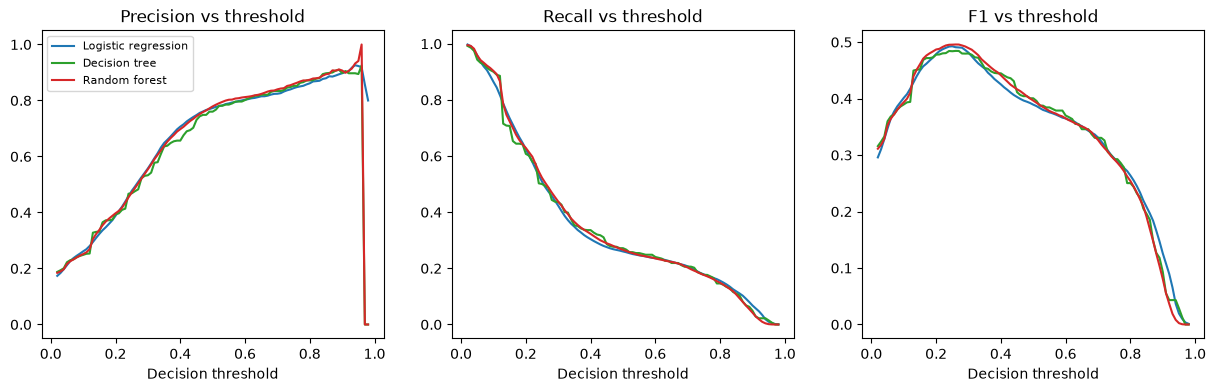

In [7]:
sec_cls = Sec("Class-specific performance")
sec_cls.p("The injury class (the minority) is what matters operationally, but the no-injury class matters too: every false alarm wastes resources. Metrics are shown per class at each model's own decision threshold chosen on validation data.")
rows = []
for m in USABLE:
    for tname, thr in [("0.5", 0.5), ("max-F1", THR_F1[m]), ("recall>=0.90", THR_R90[m])]:
        yhat = (P[m] >= thr).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
        for cls, pr_, rc_, sup in [("injury", safe_div(tp, tp + fp), safe_div(tp, tp + fn), tp + fn),
                                   ("no injury", safe_div(tn, tn + fn), safe_div(tn, tn + fp), tn + fp)]:
            f = safe_div(2 * pr_ * rc_, pr_ + rc_) if pd.notna(pr_) and pd.notna(rc_) else np.nan
            rows.append({"Model": m, "Threshold": f"{tname} ({thr:.3f})", "Class": cls, "Precision": pr_,
                         "Recall": rc_, "F1": f, "Crashes in class": int(sup)})
cls_df = pd.DataFrame(rows)
sec_cls.table(cls_df, index=False, name="Per-class metrics")

cm_rows = {}
for m in USABLE:
    yhat = (P[m] >= THR_F1[m]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    cm_rows[m] = {"True negatives": tn, "False positives (false alarms)": fp, "False negatives (missed injuries)": fn, "True positives": tp}
sec_cls.h("Confusion matrices at each model's max-F1 threshold")
sec_cls.table(pd.DataFrame(cm_rows).T, digits=0, name="Confusion matrices")

par = {m: {f"precision @ recall {r:.2f}": precision_at_recall(y, P[m], r) for r in [0.5, 0.7, 0.8, 0.9]} for m in USABLE}
sec_cls.h("Precision when you insist on catching a given share of injury crashes")
sec_cls.table(pd.DataFrame(par).T, col_dir={c: "max" for c in list(par[USABLE[0]])}, name="Precision at recall")
tk = {}
for m in USABLE:
    tk[m] = {}
    for f in [0.05, 0.10, 0.20]:
        pr_, rc_ = topk(y, P[m], f)
        tk[m][f"precision @ top {int(f*100)}%"] = pr_
        tk[m][f"recall @ top {int(f*100)}%"] = rc_
sec_cls.h("If you can only act on the highest-risk crashes")
sec_cls.table(pd.DataFrame(tk).T, col_dir={c: "max" for c in tk[USABLE[0]]}, name="Top-k alerts")
sec_cls.note("Models whose probabilities have many ties (such as a small decision tree) cannot rank crashes finely, so these top-k numbers depend on how ties are broken.")

ths = np.linspace(0.02, 0.98, 97)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for m in USABLE:
    pr_l, rc_l, f_l = [], [], []
    for t in ths:
        yhat = (P[m] >= t).astype(int)
        pr_l.append(precision_score(y, yhat, zero_division=0))
        rc_l.append(recall_score(y, yhat, zero_division=0))
        f_l.append(f1_score(y, yhat, zero_division=0))
    for a_, vals, nm in zip(ax, [pr_l, rc_l, f_l], ["Precision", "Recall", "F1"]):
        a_.plot(ths, vals, color=COLORS[m], label=m)
        a_.set(title=f"{nm} vs threshold", xlabel="Decision threshold")
ax[0].legend(fontsize=8)
sec_cls.img(fig)
b_rec = best_of(pd.Series({m: par[m]["precision @ recall 0.90"] for m in USABLE}))
FINDINGS.append(("Class-specific performance",
                 "To catch 90% of injury crashes, the precision (share of alerts that are real injuries) is "
                 + ", ".join(f"{m} {par[m]['precision @ recall 0.90']:.1%}" for m in USABLE) + f"; {b_rec} is best here."))

## 6. GENERALIZATION

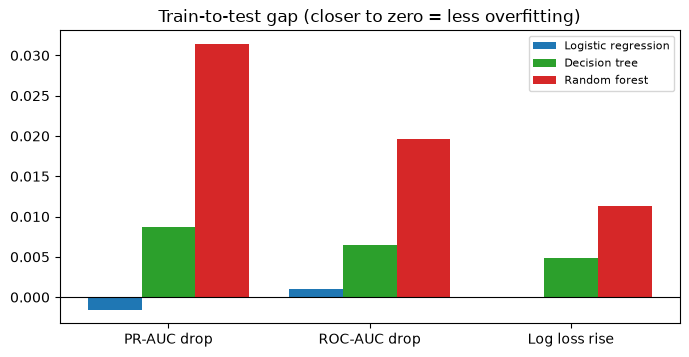

In [8]:
sec_gen = Sec("Generalization")
have_gen = [m for m in USABLE if "generalization" in ART[m]]
if have_gen:
    gap_rows, wide = {}, {}
    for m in have_gen:
        g = ART[m]["generalization"].astype(float)
        wide[m] = {f"{k} ({s})": g.loc[s, k] for k in ["pr_auc", "roc_auc", "log_loss"] for s in ["train", "val", "test"] if s in g.index}
        gap_rows[m] = {"PR-AUC drop (train minus test)": g.loc["train", "pr_auc"] - g.loc["test", "pr_auc"],
                       "ROC-AUC drop (train minus test)": g.loc["train", "roc_auc"] - g.loc["test", "roc_auc"],
                       "Log loss rise (test minus train)": g.loc["test", "log_loss"] - g.loc["train", "log_loss"]}
    sec_gen.p("A model that fits the training data much better than unseen data is overfitting. Train, validation and test scores for each model are below, followed by the train-to-test gaps (closer to zero is better).")
    sec_gen.table(pd.DataFrame(wide).T, name="Train val test")
    gap_df = pd.DataFrame(gap_rows).T
    sec_gen.table(gap_df, col_dir={c: "absmin" for c in gap_df.columns}, name="Generalization gaps")
    fig, ax = plt.subplots(figsize=(8, 3.8))
    w = 0.8 / len(have_gen)
    for i, m in enumerate(have_gen):
        ax.bar(np.arange(3) + i * w, gap_df.loc[m].values, w, color=COLORS[m], label=m)
    ax.set_xticks(np.arange(3) + w * (len(have_gen) - 1) / 2)
    ax.set_xticklabels(["PR-AUC drop", "ROC-AUC drop", "Log loss rise"])
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title("Train-to-test gap (closer to zero = less overfitting)")
    ax.legend(fontsize=8)
    sec_gen.img(fig)
    sec_gen.note("These come from a random split, so they do not test generalization over time. The seasonal and held-out-area tests in the robustness section probe that.")
    gb = gap_df["PR-AUC drop (train minus test)"].abs().idxmin()
    FINDINGS.append(("Generalization", "Train-to-test PR-AUC gap: " + ", ".join(f"{m} {gap_df.loc[m, 'PR-AUC drop (train minus test)']:+.4f}" for m in have_gen) + f". {gb} generalizes most tightly."))
else:
    sec_gen.p("Generalization files were not found.")

## 7. CALIBRATION

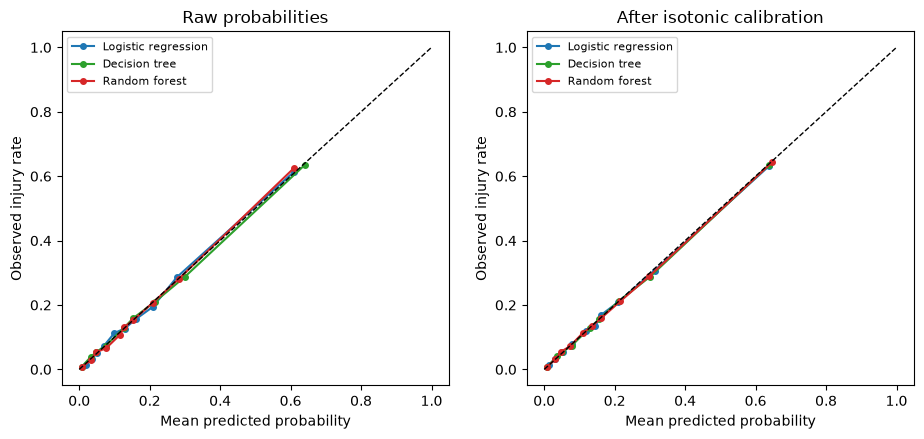

In [9]:
sec_cal = Sec("Calibration")
sec_cal.p("A calibrated model's predicted probabilities match reality: among crashes given a 30% injury risk, about 30% should involve injury. Platt scaling and isotonic regression were fit on validation data and evaluated here on the test set.")
rows = {}
for m in USABLE:
    versions = [("raw", P[m])]
    if m in P_platt:
        versions.append(("Platt", P_platt[m]))
    if m in P_iso:
        versions.append(("isotonic", P_iso[m]))
    for ver, p in versions:
        mm = metrics(y, p, THR_F1[m])
        rows[f"{m} - {ver}"] = {k: mm[k] for k in ["ece", "brier", "log_loss", "pr_auc", "roc_auc"]}
cal_df = pd.DataFrame(rows).T
sec_cal.table(cal_df, col_dir={"ece": "min", "brier": "min", "log_loss": "min", "pr_auc": "max", "roc_auc": "max"}, name="Calibration")
sec_cal.note("Lower ECE, Brier and log loss are better. Calibration methods can change PR-AUC and ROC-AUC because they alter how ties and ordering behave.")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for a_, (title, src) in zip(ax, [("Raw probabilities", P), ("After isotonic calibration", P_iso)]):
    for m in USABLE:
        if m in src:
            fr, mp = calibration_curve(y, src[m], n_bins=10, strategy="quantile")
            a_.plot(mp, fr, "o-", color=COLORS[m], label=m, ms=4)
    a_.plot([0, 1], [0, 1], "k--", lw=1)
    a_.set(title=title, xlabel="Mean predicted probability", ylabel="Observed injury rate")
    a_.legend(fontsize=8)
sec_cal.img(fig)
raw_ece = pd.Series({m: cal_df.loc[f"{m} - raw", "ece"] for m in USABLE})
best_cal = raw_ece.idxmin()
helped = []
for m in USABLE:
    for ver in ["Platt", "isotonic"]:
        k = f"{m} - {ver}"
        if k in cal_df.index and cal_df.loc[k, "ece"] < cal_df.loc[f"{m} - raw", "ece"]:
            helped.append(f"{ver} for {m}")
FINDINGS.append(("Calibration", "Raw ECE: " + ", ".join(f"{m} {raw_ece[m]:.4f}" for m in USABLE) + f"; {best_cal} is best calibrated out of the box. "
                 + ("Recalibration lowered ECE for: " + ", ".join(helped) + "." if helped else "Recalibration did not lower ECE for any model.")))

## 8. ROBUSTNESS AND SHIFT

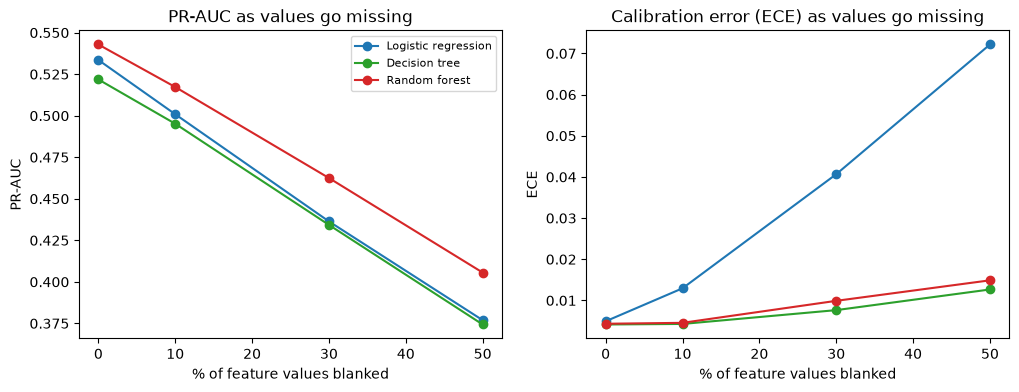

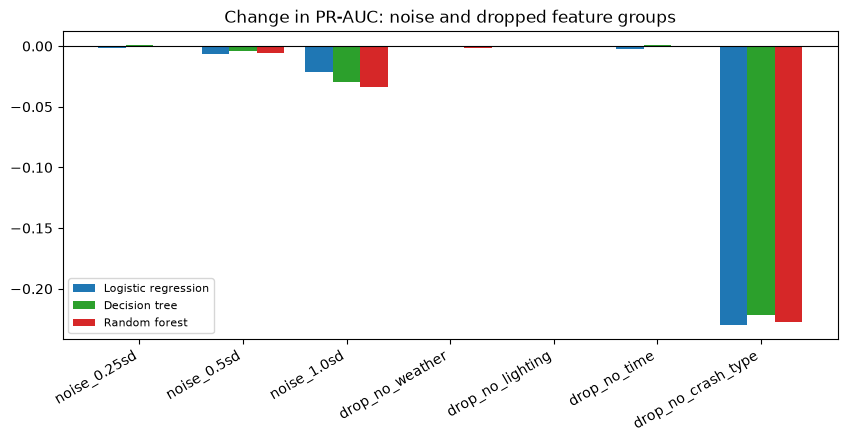

In [10]:
sec_rob = Sec("Robustness and distribution shift")
have_rob = [m for m in USABLE if "robustness_results" in ART[m]]
if have_rob:
    ROB = {m: ART[m]["robustness_results"].astype(float) for m in have_rob}
    conds = [c for c in ROB[have_rob[0]].index]
    sec_rob.p("Each model was scored on the same test crashes after randomly blanking out values, adding noise to numeric columns, or retraining without a whole feature group.")
    for metric, direction in [("pr_auc", "max"), ("log_loss", "min"), ("ece", "min")]:
        t = pd.DataFrame({m: ROB[m][metric] for m in have_rob}).reindex(conds)
        sec_rob.h(f"{metric} by condition")
        sec_rob.table(t, row_dir={c: direction for c in t.index}, name=f"Robust {metric}")
    chg = pd.DataFrame({m: ROB[m]["pr_auc"] - ROB[m].loc["clean", "pr_auc"] for m in have_rob}).reindex(conds).drop(index="clean", errors="ignore")
    sec_rob.h("Change in PR-AUC compared with the clean test set (closer to 0 is better)")
    sec_rob.table(chg, row_dir={c: "max" for c in chg.index}, name="Robust PR-AUC change")
    ret = pd.DataFrame({m: ROB[m]["pr_auc"] / ROB[m].loc["clean", "pr_auc"] for m in have_rob}).reindex(conds).drop(index="clean", errors="ignore")
    sec_rob.h("Share of clean PR-AUC retained")
    sec_rob.table(ret, row_dir={c: "max" for c in ret.index}, name="Robust retained")

    miss_c = [c for c in ["clean", "missing_10%", "missing_30%", "missing_50%"] if c in conds]
    xs = [0, 10, 30, 50][:len(miss_c)]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for m in have_rob:
        ax[0].plot(xs, [ROB[m].loc[c, "pr_auc"] for c in miss_c], "o-", color=COLORS[m], label=m)
        ax[1].plot(xs, [ROB[m].loc[c, "ece"] for c in miss_c], "o-", color=COLORS[m], label=m)
    ax[0].set(title="PR-AUC as values go missing", xlabel="% of feature values blanked", ylabel="PR-AUC")
    ax[1].set(title="Calibration error (ECE) as values go missing", xlabel="% of feature values blanked", ylabel="ECE")
    ax[0].legend(fontsize=8)
    sec_rob.img(fig)
    other_c = [c for c in chg.index if not c.startswith("missing")]
    if other_c:
        fig, ax = plt.subplots(figsize=(10, 4))
        w = 0.8 / len(have_rob)
        for i, m in enumerate(have_rob):
            ax.bar(np.arange(len(other_c)) + i * w, chg.loc[other_c, m].values, w, color=COLORS[m], label=m)
        ax.set_xticks(np.arange(len(other_c)) + w * (len(have_rob) - 1) / 2)
        ax.set_xticklabels(other_c, rotation=30, ha="right")
        ax.axhline(0, color="k", lw=0.8)
        ax.set_title("Change in PR-AUC: noise and dropped feature groups")
        ax.legend(fontsize=8)
        sec_rob.img(fig)
    sec_rob.note("Feature-group rows come from retraining the model without those columns. If the random forest used fewer trees for those retrains than for its main fit (the default), part of its gap could come from tree count rather than the missing features.")
    if "missing_30%" in ret.index:
        r30 = ret.loc["missing_30%"]
        FINDINGS.append(("Robustness to missing data", "With 30% of values missing, the share of clean PR-AUC retained is "
                         + ", ".join(f"{m} {r30[m]:.0%}" for m in have_rob) + f"; {r30.idxmax()} degrades least."))
    if "drop_no_crash_type" in chg.index:
        FINDINGS.append(("Dependence on crash type", "Removing crash type changes PR-AUC by "
                         + ", ".join(f"{m} {chg.loc['drop_no_crash_type', m]:+.3f}" for m in have_rob)
                         + " while removing weather, lighting or time changes it far less, so the models lean heavily on one feature."))
else:
    sec_rob.p("Robustness files were not found.")

have_shift = [m for m in USABLE if "shift_results" in ART[m]]
if have_shift:
    SHF = {m: ART[m]["shift_results"].astype(float) for m in have_shift}
    sec_rob.h("Distribution shift")
    sec_rob.p("Seasonal shift: train on April-October crashes, test on winter crashes. Spatial shift: hold out a quarter of police beats from training. Each shifted row is compared with its in-distribution partner.")
    sh_conds = list(SHF[have_shift[0]].index)
    for metric, direction in [("pr_auc", "max"), ("roc_auc", "max"), ("log_loss", "min"), ("ece", "min")]:
        t = pd.DataFrame({m: SHF[m][metric] for m in have_shift}).reindex(sh_conds)
        sec_rob.table(t.rename_axis(metric), row_dir={c: direction for c in t.index}, name=f"Shift {metric}")

    def pick(df, prefix):
        c = [i for i in df.index if i.startswith(prefix)]
        return c[0] if c else None
    drop_rows = {}
    for m in have_shift:
        s = SHF[m]
        w_in, w_out = pick(s, "warm->warm"), pick(s, "warm->winter")
        b_in, b_out = pick(s, "seen beats"), pick(s, "held-out beats")
        r = {}
        if w_in and w_out:
            r["Winter: ROC-AUC change"] = s.loc[w_out, "roc_auc"] - s.loc[w_in, "roc_auc"]
            r["Winter: PR-AUC change"] = s.loc[w_out, "pr_auc"] - s.loc[w_in, "pr_auc"]
            r["Winter: ECE change"] = s.loc[w_out, "ece"] - s.loc[w_in, "ece"]
        if b_in and b_out:
            r["Held-out beats: ROC-AUC change"] = s.loc[b_out, "roc_auc"] - s.loc[b_in, "roc_auc"]
            r["Held-out beats: PR-AUC change"] = s.loc[b_out, "pr_auc"] - s.loc[b_in, "pr_auc"]
            r["Held-out beats: ECE change"] = s.loc[b_out, "ece"] - s.loc[b_in, "ece"]
        drop_rows[m] = r
    drop_df = pd.DataFrame(drop_rows)
    sec_rob.h("Change under shift (shifted minus in-distribution)")
    rd = {i: ("min" if "ECE" in i else "max") for i in drop_df.index}
    sec_rob.table(drop_df, row_dir=rd, name="Shift changes")
    sec_rob.note("PR-AUC also moves with the injury rate of the test slice, which differs between winter and summer, so ROC-AUC changes are the cleaner read on shift.")
    if "Winter: ROC-AUC change" in drop_df.index:
        wr = drop_df.loc["Winter: ROC-AUC change"]
        FINDINGS.append(("Distribution shift", "Under the seasonal shift (train on warm months, test on winter) ROC-AUC changes by "
                         + ", ".join(f"{m} {wr[m]:+.4f}" for m in have_shift) + f"; {wr.idxmax()} holds up best."))
    if "Held-out beats: ROC-AUC change" in drop_df.index:
        br = drop_df.loc["Held-out beats: ROC-AUC change"]
        FINDINGS.append(("Distribution shift", "For police beats unseen in training, ROC-AUC changes by "
                         + ", ".join(f"{m} {br[m]:+.4f}" for m in have_shift) + "."))
else:
    sec_rob.p("Shift-test files were not found (logistic regression and decision tree notebooks need section 17 to have run).")

## 9. UNCERTAINTY

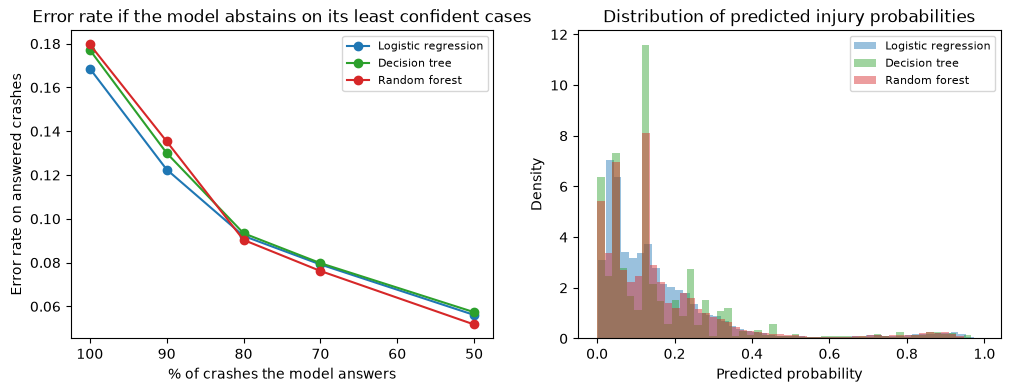

In [11]:
sec_unc = Sec("Uncertainty")
sec_unc.p("Three views of uncertainty: how wide the metric intervals are, whether the models' stated confidence is informative, and what happens if the model abstains on its least confident cases.")
ciw = {m: {k: np.percentile(BOOT[m][k], 97.5) - np.percentile(BOOT[m][k], 2.5) for k in ["roc_auc", "pr_auc", "log_loss", "f1"]} for m in USABLE}
sec_unc.h("Width of the 95% bootstrap interval (narrower = more certain)")
sec_unc.table(pd.DataFrame(ciw).T, col_dir={k: "min" for k in ["roc_auc", "pr_auc", "log_loss", "f1"]}, name="CI widths")

unc_rows = {}
sel_cov = [1.0, 0.9, 0.8, 0.7, 0.5]
sel = {m: {} for m in USABLE}
for m in USABLE:
    p = np.clip(P[m], 1e-7, 1 - 1e-7)
    ent = -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
    corr = ((p >= THR_F1[m]).astype(int) == y)
    conf = np.maximum(p, 1 - p)
    unc_rows[m] = {"Entropy when correct (bits)": ent[corr].mean(), "Entropy when wrong (bits)": ent[~corr].mean(),
                   "Entropy gap (wrong minus correct)": ent[~corr].mean() - ent[corr].mean(),
                   "Confidence when correct": conf[corr].mean(), "Confidence when wrong": conf[~corr].mean()}
    order = np.argsort(-conf, kind="stable")
    for c in sel_cov:
        k = int(c * len(y))
        sel[m][c] = 1 - corr[order[:k]].mean()
sec_unc.h("Is the model's uncertainty informative?")
unc_df = pd.DataFrame(unc_rows).T
sec_unc.table(unc_df, name="Uncertainty informativeness")
sec_unc.note("If a model knows when it is unsure, it should be less confident when it is wrong. A larger entropy gap means more informative uncertainty.")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for m in USABLE:
    ax[0].plot([c * 100 for c in sel_cov], [sel[m][c] for c in sel_cov], "o-", color=COLORS[m], label=m)
ax[0].set(title="Error rate if the model abstains on its least confident cases", xlabel="% of crashes the model answers", ylabel="Error rate on answered crashes")
ax[0].invert_xaxis()
ax[0].legend(fontsize=8)
for m in USABLE:
    ax[1].hist(P[m], bins=50, alpha=0.45, color=COLORS[m], label=m, density=True)
ax[1].set(title="Distribution of predicted injury probabilities", xlabel="Predicted probability", ylabel="Density")
ax[1].legend(fontsize=8)
sec_unc.img(fig)
sec_unc.note("The most confident predictions are mostly easy 'no injury' calls, so the error rate falling as coverage drops is partly a base-rate effect and should not be read as proof that the model handles injury crashes better when it is confident.")
FINDINGS.append(("Uncertainty", "Entropy gap between wrong and correct predictions: " + ", ".join(f"{m} {unc_df.loc[m, 'Entropy gap (wrong minus correct)']:.3f} bits" for m in USABLE)
                 + ". Bootstrap PR-AUC interval widths: " + ", ".join(f"{m} {ciw[m]['pr_auc']:.3f}" for m in USABLE) + "."))

## 10. SUBSETS

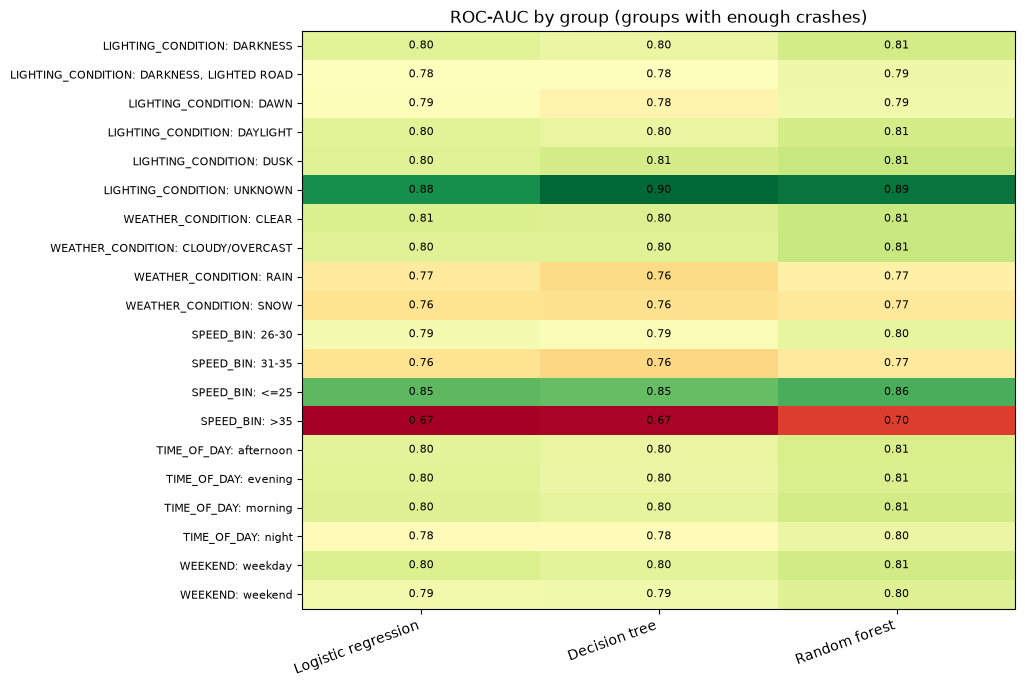

In [12]:
sec_sub = Sec("Performance across subsets")
have_sub = [m for m in USABLE if "subgroup_results" in ART[m]]
if have_sub:
    S = {}
    for m in have_sub:
        s = ART[m]["subgroup_results"].copy()
        s["label"] = s["feature"].astype(str) + ": " + s["group"].astype(str)
        S[m] = s.set_index("label")
    labels = [i for i in S[have_sub[0]].index]
    small = {l: S[have_sub[0]].loc[l, "n"] < MIN_GROUP_N for l in labels}
    disp = {l: l + (" (small n)" if small[l] else "") for l in labels}
    base = pd.DataFrame({"Crashes": [int(S[have_sub[0]].loc[l, "n"]) for l in labels],
                         "Injury rate": [S[have_sub[0]].loc[l, "injury_rate"] for l in labels]}, index=[disp[l] for l in labels])
    auc = pd.DataFrame({m: [S[m].loc[l, "roc_auc"] if l in S[m].index else np.nan for l in labels] for m in have_sub}, index=[disp[l] for l in labels])
    rec = pd.DataFrame({m: [S[m].loc[l, "recall"] if l in S[m].index else np.nan for l in labels] for m in have_sub}, index=[disp[l] for l in labels])
    gap = pd.DataFrame({m: [abs(S[m].loc[l, "mean_pred"] - S[m].loc[l, "injury_rate"]) if l in S[m].index else np.nan for l in labels] for m in have_sub}, index=[disp[l] for l in labels])
    sec_sub.p("Same test crashes, split by weather, lighting, speed limit, time of day and weekend. Groups marked small are too small to trust.")
    sec_sub.h("ROC-AUC by group (best per row highlighted)")
    sec_sub.table(pd.concat([base, auc], axis=1), row_dir={i: "max" for i in auc.index}, name="Subgroup ROC-AUC")
    sec_sub.h("Recall of injury crashes by group (at each model's own threshold)")
    sec_sub.table(rec, row_dir={i: "max" for i in rec.index}, name="Subgroup recall")
    sec_sub.h("Calibration gap by group: |average predicted risk minus actual injury rate| (smaller is better)")
    sec_sub.table(gap, row_dir={i: "min" for i in gap.index}, name="Subgroup calibration gap")
    ok_rows = [disp[l] for l in labels if not small[l]]
    fig, ax = plt.subplots(figsize=(1.4 * len(have_sub) + 5, 0.3 * len(ok_rows) + 1.5))
    hm = auc.loc[ok_rows].values.astype(float)
    im = ax.imshow(hm, aspect="auto", cmap="RdYlGn", vmin=np.nanmin(hm), vmax=np.nanmax(hm))
    ax.set_xticks(range(len(have_sub)))
    ax.set_xticklabels(have_sub, rotation=20, ha="right")
    ax.set_yticks(range(len(ok_rows)))
    ax.set_yticklabels(ok_rows, fontsize=8)
    for i in range(hm.shape[0]):
        for j in range(hm.shape[1]):
            if np.isfinite(hm[i, j]):
                ax.text(j, i, f"{hm[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title("ROC-AUC by group (groups with enough crashes)")
    sec_sub.img(fig)
    worst = {}
    for m in have_sub:
        a = auc.loc[ok_rows, m].dropna()
        worst[m] = (a.idxmin(), a.min(), a.max() - a.min())
    FINDINGS.append(("Subset performance", "Weakest well-sampled group by ROC-AUC: " + "; ".join(f"{m} on '{worst[m][0]}' ({worst[m][1]:.3f})" for m in have_sub)
                     + ". Spread between best and worst group: " + ", ".join(f"{m} {worst[m][2]:.3f}" for m in have_sub) + "."))
else:
    sec_sub.p("Subgroup files were not found.")

## 11. COMPUTATIONAL EFFICIENCY

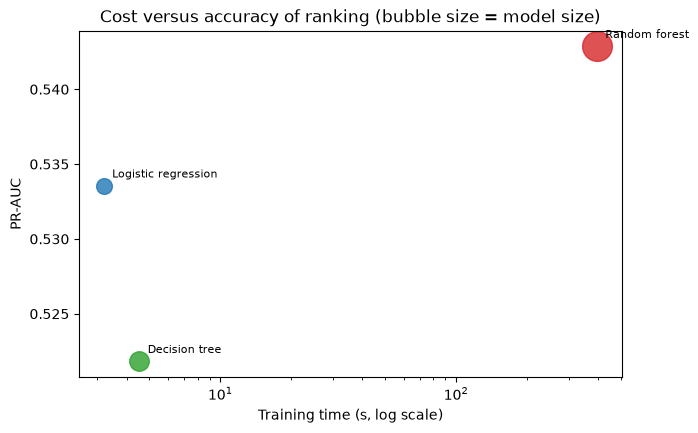

In [13]:
sec_eff = Sec("Computational efficiency")
eff = {}
for m in USABLE:
    r = RUN[m]
    eff[m] = {"Training time (s)": r.get("train_time_s", np.nan),
              "Prediction time (ms per 1,000 crashes)": r.get("inference_ms_per_1000_rows", np.nan),
              "Model size (KB)": r.get("model_size_kb", np.nan),
              "CPU cores on the machine": r.get("cpu_cores", np.nan)}
eff_df = pd.DataFrame(eff)
if eff_df.loc["Training time (s)"].notna().any():
    sec_eff.p("Measured by each model's notebook. The random forest trains on many cores while logistic regression and a single decision tree each use one, so wall-clock times understate the gap in total compute.")
    sec_eff.table(eff_df, row_dir={"Training time (s)": "min", "Prediction time (ms per 1,000 crashes)": "min", "Model size (KB)": "min"}, digits=2, name="Efficiency")
    rel = eff_df.loc[["Training time (s)", "Prediction time (ms per 1,000 crashes)", "Model size (KB)"]]
    rel = rel.div(rel.min(axis=1), axis=0)
    sec_eff.h("Cost relative to the cheapest model (1.0 = cheapest)")
    sec_eff.table(rel, digits=1, name="Relative cost")
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for m in USABLE:
        ax.scatter(eff_df.loc["Training time (s)", m], SC["pr_auc"][m], s=60 + 400 * np.log10(max(eff_df.loc["Model size (KB)", m], 1)) / 5, color=COLORS[m], alpha=0.8)
        ax.annotate(m, (eff_df.loc["Training time (s)", m], SC["pr_auc"][m]), textcoords="offset points", xytext=(6, 6), fontsize=8)
    ax.set_xscale("log")
    ax.set(title="Cost versus accuracy of ranking (bubble size = model size)", xlabel="Training time (s, log scale)", ylabel="PR-AUC")
    sec_eff.img(fig)
    t_ = eff_df.loc["Training time (s)"]
    FINDINGS.append(("Computational cost", "Training time: " + ", ".join(f"{m} {t_[m]:,.1f}s" for m in USABLE)
                     + "; model size: " + ", ".join(f"{m} {eff_df.loc['Model size (KB)', m]:,.0f} KB" for m in USABLE) + "."))
else:
    sec_eff.p("Run-info files were not found, so timing and size are unavailable.")

## 12. INTERPRETABILITY

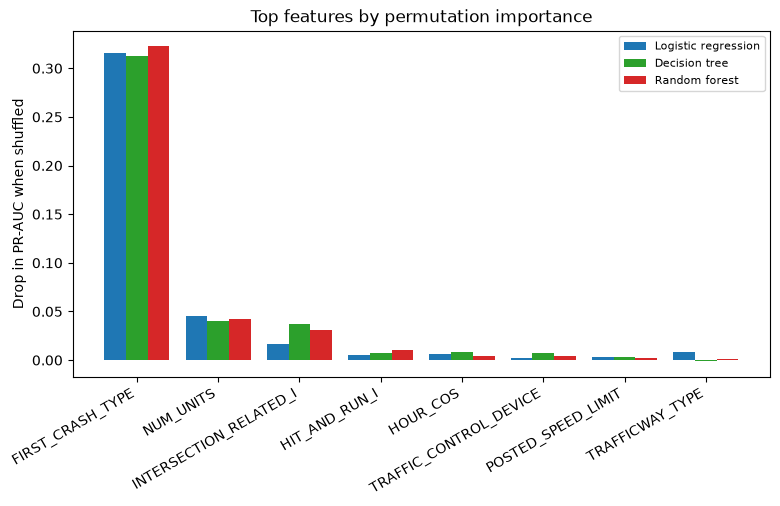

In [14]:
sec_int = Sec("Interpretability")
have_pi = [m for m in USABLE if "permutation_importance" in ART[m]]
PI = {}
if have_pi:
    for m in have_pi:
        PI[m] = ART[m]["permutation_importance"].set_index("feature")["importance"].astype(float)
    pi_df = pd.DataFrame(PI).fillna(0.0)
    pi_df = pi_df.loc[pi_df.mean(axis=1).sort_values(ascending=False).index]
    sec_int.p("Permutation importance: how much PR-AUC falls on test data when one feature's values are shuffled. Every model was measured the same way, so the numbers are comparable.")
    sec_int.table(pi_df, col_dir={m: "max" for m in have_pi}, name="Permutation importance")
    share = pi_df.clip(lower=0)
    share = share.div(share.sum(axis=0), axis=1)
    sec_int.h("Share of total importance")
    sec_int.table(share, name="Importance share")
    top = pi_df.head(8)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    w = 0.8 / len(have_pi)
    for i, m in enumerate(have_pi):
        ax.bar(np.arange(len(top)) + i * w, top[m].values, w, color=COLORS[m], label=m)
    ax.set_xticks(np.arange(len(top)) + w * (len(have_pi) - 1) / 2)
    ax.set_xticklabels(top.index, rotation=30, ha="right")
    ax.set(title="Top features by permutation importance", ylabel="Drop in PR-AUC when shuffled")
    ax.legend(fontsize=8)
    sec_int.img(fig)

    grp = {}
    for g, feats in FEATURE_GROUPS.items():
        grp[g] = {m: pi_df.reindex(feats)[m].clip(lower=0).sum() for m in have_pi}
    grp_df = pd.DataFrame(grp).T
    grp_df = grp_df.loc[grp_df.mean(axis=1).sort_values(ascending=False).index]
    sec_int.h("Grouped importance (sum of member features)")
    sec_int.table(grp_df, col_dir={m: "max" for m in have_pi}, name="Grouped importance")
    sec_int.note("Importance is split across correlated columns (for example the three hour columns), so single-feature numbers understate those effects. Grouping is approximate because importances of correlated features do not add exactly.")
    if len(have_pi) >= 2:
        rc = pi_df.corr(method="spearman")
        sec_int.h("Do the models agree on which features matter? (rank correlation)")
        sec_int.table(rc, digits=2, name="Importance rank correlation")
        top3 = {m: set(pi_df[m].sort_values(ascending=False).head(3).index) for m in have_pi}
        sec_int.p("Top three features per model: " + "; ".join(f"{m}: {', '.join(sorted(top3[m]))}" for m in have_pi) + ".")
        FINDINGS.append(("Interpretability", "Most important feature by permutation importance: "
                         + ", ".join(f"{m} {pi_df[m].idxmax()} ({pi_df[m].max():.3f})" for m in have_pi)
                         + ". Rank correlation of feature importance between models ranges from "
                         + f"{rc.values[np.triu_indices(len(rc), 1)].min():.2f} to {rc.values[np.triu_indices(len(rc), 1)].max():.2f}."))
else:
    sec_int.p("Permutation importance files were not found.")

for m, label in [("Logistic regression", "coefficients")]:
    if m in USABLE and "coefficients" in ART[m]:
        c = ART[m]["coefficients"].copy()
        c["coef"] = c["coef"].astype(float)
        c["odds_ratio"] = c["odds_ratio"].astype(float)
        c = c.reindex(c["coef"].abs().sort_values(ascending=False).index).head(12)
        sec_int.h("Logistic regression: largest effects (odds ratio above 1 raises injury odds)")
        sec_int.table(c.set_index("feature")[["coef", "odds_ratio"]], digits=3, name="LR coefficients")
for m in USABLE:
    imp = ART[m].get("importance")
    if imp is not None and "importance" in imp.columns:
        t = imp.head(10).copy()
        t["importance"] = t["importance"].astype(float)
        sec_int.h(f"{m}: top impurity-based importances (one-hot level)")
        sec_int.table(t.set_index("feature"), digits=4, name=f"{m[:12]} impurity")
for m, txt in RULES.items():
    if m in USABLE:
        sec_int.h(f"{m}: the top of the tree as if/then rules")
        sec_int.raw("<pre>" + html.escape("\n".join(txt.splitlines()[:45])) + "</pre>")
sec_int.note(f"Interpretability scores used in the scenario analysis (1 = opaque, 5 = fully readable) are a judgment, not a measurement: "
             + ", ".join(f"{m} {INTERPRETABILITY_SCORE.get(m, '?')}" for m in USABLE) + ".")

## 13. SCENARIO SELECTION

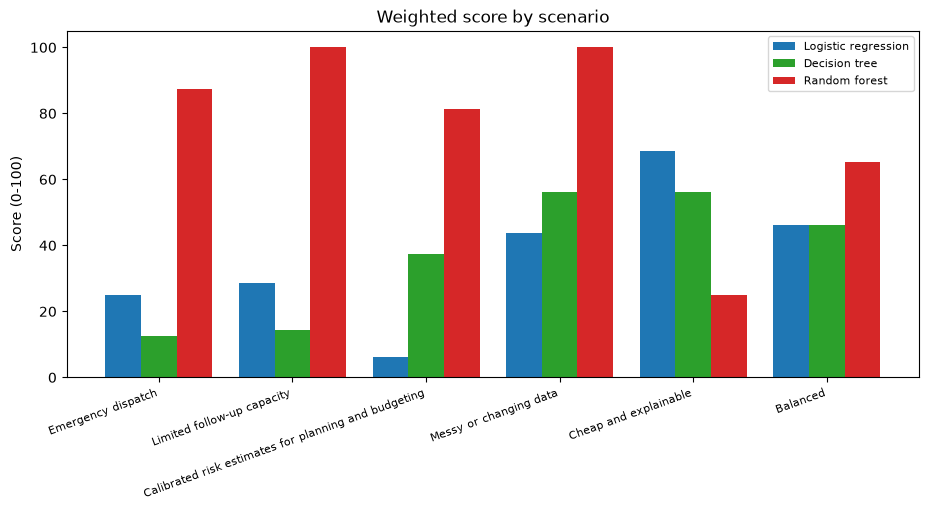

In [15]:
sec_scn = Sec("Choosing a model by scenario")
DIM = pd.DataFrame(index=USABLE, dtype=float)
HIGHER = {"pr_auc": True, "roc_auc": True, "log_loss": False, "ece": False, "precision_at_recall90": True,
          "precision_at_top10": True, "robust_missing30": True, "robust_shift": True, "worst_group_auc": True,
          "train_time": False, "inference_time": False, "model_size": False, "interpretability": True}
NICE = {"pr_auc": "PR-AUC", "roc_auc": "ROC-AUC", "log_loss": "Log loss", "ece": "Calibration error (ECE)",
        "precision_at_recall90": "Precision at 90% recall", "precision_at_top10": "Precision in top 10% flagged",
        "robust_missing30": "PR-AUC kept at 30% missing", "robust_shift": "ROC-AUC kept under winter shift",
        "worst_group_auc": "Worst-group ROC-AUC", "train_time": "Training time", "inference_time": "Prediction time",
        "model_size": "Model size", "interpretability": "Interpretability (judgment)"}
DIM["pr_auc"] = pd.Series({m: SC["pr_auc"][m] for m in USABLE})
DIM["roc_auc"] = pd.Series({m: SC["roc_auc"][m] for m in USABLE})
DIM["log_loss"] = pd.Series({m: SC["log_loss"][m] for m in USABLE})
DIM["ece"] = pd.Series({m: SC["ece"][m] for m in USABLE})
DIM["precision_at_recall90"] = pd.Series({m: SC["precision @ recall 0.90 (any threshold)"][m] for m in USABLE})
DIM["precision_at_top10"] = pd.Series({m: SC["precision @ top 10% of crashes flagged"][m] for m in USABLE})
if have_rob and "missing_30%" in ret.index:
    DIM["robust_missing30"] = pd.Series({m: ret.loc["missing_30%", m] for m in have_rob})
if have_shift and "Winter: ROC-AUC change" in drop_df.index:
    DIM["robust_shift"] = pd.Series({m: 1 + drop_df.loc["Winter: ROC-AUC change", m] / SHF[m].loc[pick(SHF[m], "warm->warm"), "roc_auc"] for m in have_shift})
if have_sub:
    DIM["worst_group_auc"] = pd.Series({m: worst[m][1] for m in have_sub})
if eff_df.loc["Training time (s)"].notna().all():
    DIM["train_time"] = eff_df.loc["Training time (s)"]
    DIM["inference_time"] = eff_df.loc["Prediction time (ms per 1,000 crashes)"]
    DIM["model_size"] = eff_df.loc["Model size (KB)"]
DIM["interpretability"] = pd.Series({m: float(INTERPRETABILITY_SCORE.get(m, np.nan)) for m in USABLE})
DIM = DIM.dropna(axis=1)

SCORES = pd.DataFrame({d: cluster_scores(DIM[d], HIGHER[d]) for d in DIM.columns}).reindex(USABLE)
dropped = [d for d in HIGHER if d not in DIM.columns]
sec_scn.p("There is no single best model: the right choice depends on what the model is for. Below, each dimension is scored 1.0 for the best model, 0.0 for the worst, and in between for the rest (models within 1% of each other count as tied). Scenarios weight the dimensions that matter most for them.")
sec_scn.h("Underlying numbers for each dimension")
sec_scn.table(DIM.T.rename(index=NICE), row_dir={NICE[d]: ("max" if HIGHER[d] else "min") for d in DIM.columns}, digits=4, name="Scenario inputs")
sec_scn.h("Dimension scores (1 = best, 0 = worst)")
sec_scn.table(SCORES.T.rename(index=NICE), row_dir={NICE[d]: "max" for d in SCORES.columns}, digits=2, name="Scenario scores")
if dropped:
    sec_scn.note("Dimensions left out because some result files were missing: " + ", ".join(NICE[d] for d in dropped) + ".")

scn_rows = {}
for name, wts in SCENARIOS.items():
    use = {d: w for d, w in wts.items() if d in SCORES.columns}
    if not use:
        continue
    tot = sum(use.values())
    scn_rows[name] = {m: 100 * sum(SCORES.loc[m, d] * w for d, w in use.items()) / tot for m in USABLE}
scn_df = pd.DataFrame(scn_rows).T
scn_df["Recommended"] = scn_df[USABLE].idxmax(axis=1)
close = []
for name in scn_df.index:
    v = scn_df.loc[name, USABLE].sort_values(ascending=False)
    close.append("yes" if len(v) > 1 and (v.iloc[0] - v.iloc[1]) < 5 else "")
scn_df["Close call (under 5 points)?"] = close
sec_scn.h("Scenario scores (0-100) and recommended model")
sec_scn.table(scn_df, row_dir={}, digits=1, name="Scenario winners")
wtxt = pd.DataFrame({name: {NICE[d]: w for d, w in wts.items() if d in SCORES.columns} for name, wts in SCENARIOS.items()}).fillna(0).astype(int)
sec_scn.h("Weights used (edit SCENARIOS in the config cell to change them)")
sec_scn.table(wtxt, digits=0, name="Scenario weights")
fig, ax = plt.subplots(figsize=(11, 4.5))
w = 0.8 / len(USABLE)
for i, m in enumerate(USABLE):
    ax.bar(np.arange(len(scn_df)) + i * w, scn_df[m].values, w, color=COLORS[m], label=m)
ax.set_xticks(np.arange(len(scn_df)) + w * (len(USABLE) - 1) / 2)
ax.set_xticklabels([n.split(" (")[0] for n in scn_df.index], rotation=20, ha="right", fontsize=8)
ax.set(title="Weighted score by scenario", ylabel="Score (0-100)")
ax.legend(fontsize=8)
sec_scn.img(fig)
sec_scn.note("These scores rank models relative to each other on this data. They show how the choice flips with the use case and which trade-offs are involved; they do not say any model is good enough to deploy.")
for name in scn_df.index:
    FINDINGS.append(("Scenario: " + name.split(" (")[0], f"{scn_df.loc[name, 'Recommended']} scores highest ({scn_df.loc[name, scn_df.loc[name, 'Recommended']]:.0f}/100)"
                     + (" in a close call." if scn_df.loc[name, "Close call (under 5 points)?"] else ".")))

## 14. WRITE THE REPORT

Writes `model_comparison_report.html` (and optionally an Excel file of every table).

In [16]:
CSS = """
body{font-family:-apple-system,Segoe UI,Helvetica,Arial,sans-serif;max-width:1100px;margin:2rem auto;padding:0 1rem;color:#1b1b1b;line-height:1.5}
h1{font-size:1.9rem;margin-bottom:.2rem} h2{margin-top:2.6rem;border-bottom:2px solid #ddd;padding-bottom:.3rem}
h3{margin-top:1.6rem;font-size:1.05rem}
.tbl{overflow-x:auto;margin:.6rem 0 1rem} table{border-collapse:collapse;font-size:.85rem}
th,td{border:1px solid #ddd;padding:.3rem .55rem;text-align:right;white-space:nowrap} th{background:#f3f3f3;text-align:left}
td.best{background:#e6f4ea} img{max-width:100%;height:auto;margin:.6rem 0}
.note{color:#555;font-size:.88rem} .warn{background:#fff3cd;border:1px solid #e0c36a;padding:.7rem 1rem;border-radius:6px}
nav a{display:inline-block;margin:.15rem .6rem .15rem 0} pre{background:#f6f6f6;padding:.8rem;overflow-x:auto;font-size:.8rem}
li{margin:.35rem 0}
@media (prefers-color-scheme: dark){body{background:#161616;color:#e8e8e8} th{background:#262626} th,td{border-color:#444}
td.best{background:#1f3b2a} .warn{background:#3b3320;border-color:#6b5a1e} h2{border-color:#444} .note{color:#aaa} pre{background:#222}}
"""
sec_find = Sec("Key findings")
by_dim = {}
for dim_, txt in FINDINGS:
    by_dim.setdefault(dim_, []).append(txt)
sec_find.raw("<ul>" + "".join(f"<li><b>{html.escape(d)}.</b> {html.escape(' '.join(t))}</li>" for d, t in by_dim.items()) + "</ul>")
sec_find.note("Generated from the result files. Check each statement against the tables before using it in your write-up.")

ORDER = [sec_find, sec_score, sec_data, sec_pred, sec_cls, sec_gen, sec_cal, sec_rob, sec_unc, sec_sub, sec_eff, sec_int, sec_scn]
toc = "<nav>" + "".join(f'<a href="#{s.anchor}">{html.escape(s.title)}</a>' for s in ORDER) + "</nav>"
warn = ""
if WARNINGS:
    warn = '<div class="warn"><b>Warnings</b><ul>' + "".join(f"<li>{html.escape(w)}</li>" for w in WARNINGS) + "</ul></div>"
doc = (f"<!DOCTYPE html><html lang='en'><head><meta charset='utf-8'><title>Model comparison: Chicago crash injury prediction</title>"
       f"<style>{CSS}</style></head><body><h1>Model comparison: Chicago crash injury prediction</h1>"
       f"<p class='note'>Models: {html.escape(', '.join(USABLE))}. Test crashes: {len(y):,} (injury rate {y.mean():.1%}).</p>{warn}{toc}"
       + "".join(s.html() for s in ORDER) + "</body></html>")
out_path = os.path.join(FOLDER, OUTPUT_HTML)
with open(out_path, "w", encoding="utf-8") as f:
    f.write(doc)
print("\nWrote", os.path.abspath(out_path), f"({os.path.getsize(out_path) / 1e6:.1f} MB)")
for w in WARNINGS:
    print("WARNING:", w)
if ALSO_EXPORT_EXCEL:
    xl = os.path.join(FOLDER, "model_comparison_tables.xlsx")
    with pd.ExcelWriter(xl) as xw:
        for nm, t in TABLES.items():
            t.to_excel(xw, sheet_name=nm)
    print("Wrote", os.path.abspath(xl))
print("\nKey findings:")
for d, t in by_dim.items():
    print(f"- {d}: {' '.join(t)}")


Wrote /Users/kirraorndorff/Desktop/School/assignment_6/model_comparison_report.html (0.9 MB)

Key findings:
- Metric choice: 3 different model(s) come out on top depending on the metric; across 20 metrics, Logistic regression wins 3, Decision tree wins 4, Random forest wins 13.
- Accuracy: Always predicting 'no injury' scores 83.4% accuracy. At the default 0.5 threshold the models score Logistic regression 86.5%, Decision tree 86.5%, Random forest 86.6%, but their recall is 26%, 27%, 27%, so accuracy hides how many injury crashes are missed.
- Predictive performance: By PR-AUC, Random forest is best (0.5429). The paired bootstrap shows it is clearly ahead of every other model. By log loss, Random forest is best (0.3456). The paired bootstrap shows it is clearly ahead of every other model. By ROC-AUC, Random forest is best (0.8083). The paired bootstrap shows it is clearly ahead of every other model.
- Class-specific performance: To catch 90% of injury crashes, the precision (share of 